Bai 1: Du doan gia nha tu dien tich
He so goc: 35.04
He so chan: 497.49
MSE: 536.71
R2 score: 0.9998


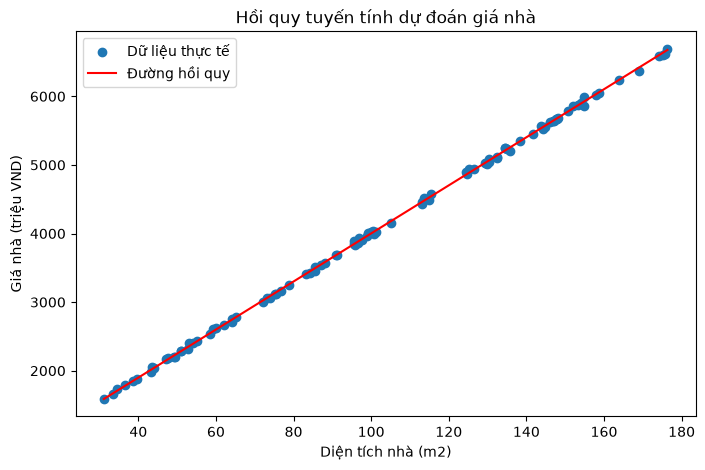

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score

def tao_du_lieu(n_mau=100,do_nhieu=25, seed=42):
    rng=np.random.default_rng(seed)
    dien_tich=rng.uniform(30,180,n_mau)
    gia_nha=500+35*dien_tich+rng.normal(0,do_nhieu,n_mau)
    return pd.DataFrame({
        "Dien_tich": dien_tich,
        "Gia_nha": gia_nha
    })

def huan_luyen_va_danh_gia(X,y):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

    model=LinearRegression()
    model.fit(X_train,y_train)

    y_pred=model.predict(X_test)

    mse=mean_squared_error(y_test,y_pred)
    r2=r2_score(y_test,y_pred)
    return model,X_test, y_test, y_pred, mse, r2


data=tao_du_lieu(n_mau=100, do_nhieu=25)

X=data[["Dien_tich"]]
y=data["Gia_nha"]

model,X_test,y_test,y_pred,mse,r2=huan_luyen_va_danh_gia(X,y)

print("Bai 1: Du doan gia nha tu dien tich")
print(f"He so goc: {model.coef_[0]:.2f}")
print(f"He so chan: {model.intercept_:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R2 score: {r2:.4f}")

x_line = np.linspace(data["Dien_tich"].min(), data["Dien_tich"].max(), 100)
y_line = model.predict(pd.DataFrame({"Dien_tich": x_line}))

plt.figure(figsize=(8, 5))
plt.scatter(data["Dien_tich"], data["Gia_nha"], label="Dữ liệu thực tế")
plt.plot(x_line, y_line, color="red", label="Đường hồi quy")
plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá nhà (triệu VND)")
plt.title("Hồi quy tuyến tính dự đoán giá nhà")
plt.legend()
plt.show()


In [4]:
ket_qua=[]
for n_mau in[30,100,500,1000]:
    for do_nhieu in [10,30,50,500]:
        data_thu=tao_du_lieu(
            n_mau=n_mau,
            do_nhieu=do_nhieu,
            seed=42
        )
        _,_,_,_,mse_thu,r2_thu=huan_luyen_va_danh_gia(data_thu[["Dien_tich"]], data_thu["Gia_nha"])
        ket_qua.append({
            "So mau":n_mau,
            "Do nhieu":do_nhieu,
            "MSE": mse_thu,
            "R2 Score": r2_thu
        })
bang_ket_qua=pd.DataFrame(ket_qua)
print("Bai 2: Anh huong cua so mau va do nhieu")
print(bang_ket_qua.round(3).to_string(index=False))

Bai 2: Anh huong cua so mau va do nhieu
 So mau  Do nhieu        MSE  R2 Score
     30        10     60.637     1.000
     30        30    545.735     1.000
     30        50   1515.931     0.999
     30       500 151593.088     0.932
    100        10     85.874     1.000
    100        30    772.868     1.000
    100        50   2146.856     0.999
    100       500 214685.582     0.905
    500        10     93.746     1.000
    500        30    843.711     1.000
    500        50   2343.641     0.999
    500       500 234364.051     0.915
   1000        10    122.740     1.000
   1000        30   1104.656     1.000
   1000        50   3068.490     0.999
   1000       500 306848.996     0.890


In [13]:
rng=np.random.default_rng(42)
n_mau=500
dien_tich=rng.uniform(30,180,n_mau)
so_phong_ngu=rng.integers(1,6,n_mau)
khoang_cach_trung_tam=rng.uniform(1,30,n_mau)
tuoi_nha=rng.integers(5,10,n_mau)

gia_nha=(
    300
    +30*dien_tich
    +120*so_phong_ngu
    -18*khoang_cach_trung_tam
    -8*tuoi_nha
    +rng.normal(0,35,n_mau)
)

data_nhieu_bien=pd.DataFrame({
    "Dien_tich":dien_tich,
    "So_phong_ngu":so_phong_ngu,
    "Khoang_cach_trung_tam":khoang_cach_trung_tam,
    "Tuoi_nha":tuoi_nha,
    "Gia_nha":gia_nha
})

mode_don,_,_,_,mse_don,r2_don=huan_luyen_va_danh_gia(
    data_nhieu_bien[["Dien_tich"]],
    data_nhieu_bien["Gia_nha"]
)

cac_dac_trung=[
    "Dien_tich",
    "So_phong_ngu",
    "Khoang_cach_trung_tam",
    "Tuoi_nha"
]

model_nhieu,_,_,_,mse_nhieu,r2_nhieu=huan_luyen_va_danh_gia(
    data_nhieu_bien[cac_dac_trung],
    data_nhieu_bien["Gia_nha"]
)
print("\nBai3: So sanh mo hinh")
print(pd.DataFrame([
    {
        "Mo hinh": "Chi dung dien tich",
        "MSE": mse_don,
        "R2 score": r2_don
    },
    {
        "Mo hinh": "Dung nhieu dac trung",
        "MSE": mse_nhieu,
        "R2 score": r2_nhieu
    }
]).round(3).to_string(index=False))

print("\nHe so cua mo hinh nhieu dac trung:")
for ten_dac_trung, he_so in zip(cac_dac_trung, model_nhieu.coef_):
    print(f"{ten_dac_trung}: {he_so:.2f}")


Bai3: So sanh mo hinh
             Mo hinh       MSE  R2 score
  Chi dung dien tich 44771.459     0.977
Dung nhieu dac trung  1215.259     0.999

He so cua mo hinh nhieu dac trung:
Dien_tich: 29.95
So_phong_ngu: 120.11
Khoang_cach_trung_tam: -17.56
Tuoi_nha: -7.35
